In [ ]:
import gymnasium as gym

# Create the environment
env = gym.make("Taxi-v4")

# 1. Size of the state and action space
print("Observation space:", env.observation_space)   # Discrete(500)
print("Action space:", env.action_space)             # Discrete(6)

# 2. Start an episode
state, info = env.reset(seed=42)
print("\nStart state number:", state)

# 3. Decode the state number into its three parts
taxi_row, taxi_col, passenger_loc, destination = env.unwrapped.decode(state)
print("Taxi row:", taxi_row, "| Taxi col:", taxi_col)
print("Passenger location (0=R,1=G,2=Y,3=B,4=in taxi):", passenger_loc)
print("Destination (0=R,1=G,2=Y,3=B):", destination)

# 4. Take a few random actions and watch the rewards
print("\nRandom steps:")
for step in range(10):
    action = env.action_space.sample()
    next_state, reward, terminated, truncated, info = env.step(action)
    print(f"Step {step+1}: action={action}, reward={reward}, "
          f"terminated={terminated}, truncated={truncated}")
    if terminated or truncated:
        break

env.close()

Observation space: Discrete(500)
Action space: Discrete(6)

Start state number: 386
Taxi row: 3 | Taxi col: 4
Passenger location (0=R,1=G,2=Y,3=B,4=in taxi): 1
Destination (0=R,1=G,2=Y,3=B): 2

Random steps:
Step 1: action=1, reward=-1, terminated=False, truncated=False
Step 2: action=0, reward=-1, terminated=False, truncated=False
Step 3: action=0, reward=-1, terminated=False, truncated=False
Step 4: action=3, reward=-1, terminated=False, truncated=False
Step 5: action=5, reward=-10, terminated=False, truncated=False
Step 6: action=3, reward=-1, terminated=False, truncated=False
Step 7: action=4, reward=-10, terminated=False, truncated=False
Step 8: action=0, reward=-1, terminated=False, truncated=False
Step 9: action=5, reward=-10, terminated=False, truncated=False
Step 10: action=0, reward=-1, terminated=False, truncated=False


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import gymnasium as gym


def train(alpha=0.1, gamma=0.99, eps_start=1.0, eps_min=0.01,
          eps_decay=0.999, episodes=10000, seed=0):
    """Train a Q-Learning agent on Taxi-v3 and return the Q-table and logs."""
    env = gym.make("Taxi-v3")
    n_states = env.observation_space.n      # 500
    n_actions = env.action_space.n          # 6
    rng = np.random.default_rng(seed)

    Q = np.zeros((n_states, n_actions))     # Q-table starts with all zeros
    epsilon = eps_start

    episode_rewards = []    # total reward of each episode
    episode_success = []    # 1 if passenger was dropped correctly, else 0

    for ep in range(episodes):
        state, _ = env.reset(seed=seed if ep == 0 else None)
        total_reward = 0
        done = False

        while not done:
            # epsilon-greedy action selection
            if rng.random() < epsilon:
                action = int(rng.integers(n_actions))   # explore
            else:
                action = int(np.argmax(Q[state]))       # exploit

            next_state, reward, terminated, truncated, _ = env.step(action)

            # Q-Learning update:
            # Q(s,a) <- Q(s,a) + alpha * [ r + gamma * max Q(s',a') - Q(s,a) ]
            # If the episode really ended (terminated), there is no next value.
            best_next = np.max(Q[next_state])
            target = reward + gamma * best_next * (1 - int(terminated))
            Q[state, action] += alpha * (target - Q[state, action])

            state = next_state
            total_reward += reward
            done = terminated or truncated

        episode_rewards.append(total_reward)
        episode_success.append(int(terminated))

        # reduce epsilon after every episode
        epsilon = max(eps_min, epsilon * eps_decay)

    env.close()
    return Q, np.array(episode_rewards), np.array(episode_success)


def evaluate(Q=None, episodes=100, seed=1000):
    """Run episodes with no exploration (epsilon = 0).
    If Q is None, a random agent is used (baseline)."""
    env = gym.make("Taxi-v3")
    rng = np.random.default_rng(seed)
    rewards, steps, successes = [], [], []

    for ep in range(episodes):
        state, _ = env.reset(seed=seed + ep)
        total_reward, n_steps, done = 0, 0, False

        while not done:
            if Q is None:
                action = int(rng.integers(env.action_space.n))
            else:
                action = int(np.argmax(Q[state]))      # pure exploitation

            state, reward, terminated, truncated, _ = env.step(action)
            total_reward += reward
            n_steps += 1
            done = terminated or truncated

        rewards.append(total_reward)
        steps.append(n_steps)
        successes.append(int(terminated))

    env.close()
    return {
        "avg_reward": float(np.mean(rewards)),
        "avg_steps": float(np.mean(steps)),
        "success_rate": 100 * float(np.mean(successes)),
    }

In [ ]:
import numpy as np
import gymnasium as gym

# Redefine the train and evaluate functions with Taxi-v4
def train(alpha=0.1, gamma=0.99, eps_start=1.0, eps_min=0.01,
          eps_decay=0.999, episodes=10000, seed=0):
    env = gym.make("Taxi-v4")
    n_states = env.observation_space.n
    n_actions = env.action_space.n
    rng = np.random.default_rng(seed)
    Q = np.zeros((n_states, n_actions))
    epsilon = eps_start
    episode_rewards = []
    episode_success = []

    for ep in range(episodes):
        state, _ = env.reset(seed=seed if ep == 0 else None)
        total_reward = 0
        done = False

        while not done:
            if rng.random() < epsilon:
                action = int(rng.integers(n_actions))
            else:
                action = int(np.argmax(Q[state]))

            next_state, reward, terminated, truncated, _ = env.step(action)
            best_next = np.max(Q[next_state])
            target = reward + gamma * best_next * (1 - int(terminated))
            Q[state, action] += alpha * (target - Q[state, action])

            state = next_state
            total_reward += reward
            done = terminated or truncated

        episode_rewards.append(total_reward)
        episode_success.append(int(terminated))
        epsilon = max(eps_min, epsilon * eps_decay)

    env.close()
    return Q, np.array(episode_rewards), np.array(episode_success)

def evaluate(Q=None, episodes=100, seed=1000):
    env = gym.make("Taxi-v4")
    rng = np.random.default_rng(seed)
    rewards, steps, successes = [], [], []

    for ep in range(episodes):
        state, _ = env.reset(seed=seed + ep)
        total_reward, n_steps, done = 0, 0, False

        while not done:
            if Q is None:
                action = int(rng.integers(env.action_space.n))
            else:
                action = int(np.argmax(Q[state]))

            state, reward, terminated, truncated, _ = env.step(action)
            total_reward += reward
            n_steps += 1
            done = terminated or truncated

        rewards.append(total_reward)
        steps.append(n_steps)
        successes.append(int(terminated))

    env.close()
    return {
        "avg_reward": float(np.mean(rewards)),
        "avg_steps": float(np.mean(steps)),
        "success_rate": 100 * float(np.mean(successes)),
    }

# Hyperparameters
ALPHA = 0.1          # learning rate
GAMMA = 0.99         # discount factor
EPS_START = 1.0      # start with full exploration
EPS_MIN = 0.01       # never go below 1% exploration
EPS_DECAY = 0.999    # epsilon is multiplied by this after each episode
EPISODES = 10000

Q, rewards, successes = train(ALPHA, GAMMA, EPS_START, EPS_MIN,
                              EPS_DECAY, EPISODES, seed=0)

print("Training finished.")
print("Q-table shape:", Q.shape)
print("Average reward, last 100 training episodes:", rewards[-100:].mean())

Training finished.
Q-table shape: (500, 6)
Average reward, last 100 training episodes: 7.97


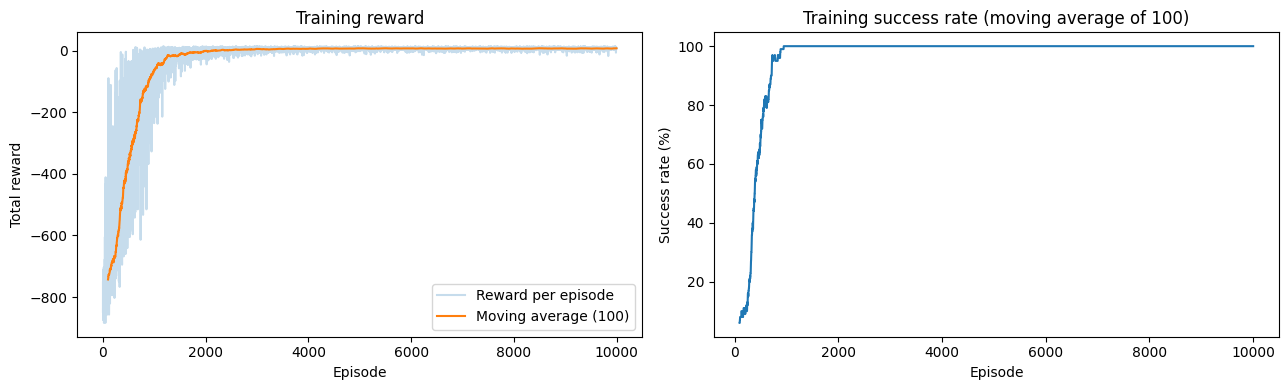

Moving average reward first reached 0 at episode ~2107


In [ ]:
def moving_average(x, window=100):
    return np.convolve(x, np.ones(window) / window, mode="valid")

window = 100
ma_reward = moving_average(rewards, window)
ma_success = moving_average(successes, window) * 100

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].plot(rewards, alpha=0.25, label="Reward per episode")
axes[0].plot(range(window - 1, len(rewards)), ma_reward, label="Moving average (100)")
axes[0].set_xlabel("Episode")
axes[0].set_ylabel("Total reward")
axes[0].set_title("Training reward")
axes[0].legend()

axes[1].plot(range(window - 1, len(successes)), ma_success)
axes[1].set_xlabel("Episode")
axes[1].set_ylabel("Success rate (%)")
axes[1].set_title("Training success rate (moving average of 100)")

plt.tight_layout()
plt.savefig("training_results.png", dpi=150)
plt.show()

# When did the agent start to do well?
threshold = 0
reached = np.where(ma_reward >= threshold)[0]
if len(reached) > 0:
    print(f"Moving average reward first reached {threshold} at episode ~{reached[0] + window}")
else:
    print("Threshold not reached")

In [ ]:
trained = evaluate(Q, episodes=100)
random_agent = evaluate(None, episodes=100)

print("Trained Q-Learning agent (100 test episodes, epsilon = 0)")
print(f"  Average reward : {trained['avg_reward']:.2f}")
print(f"  Average steps  : {trained['avg_steps']:.2f}")
print(f"  Success rate   : {trained['success_rate']:.0f}%")

print("\nRandom agent (baseline, 100 episodes)")
print(f"  Average reward : {random_agent['avg_reward']:.2f}")
print(f"  Average steps  : {random_agent['avg_steps']:.2f}")
print(f"  Success rate   : {random_agent['success_rate']:.0f}%")

Trained Q-Learning agent (100 test episodes, epsilon = 0)
  Average reward : 7.63
  Average steps  : 13.37
  Success rate   : 100%

Random agent (baseline, 100 episodes)
  Average reward : -758.03
  Average steps  : 194.30
  Success rate   : 7%


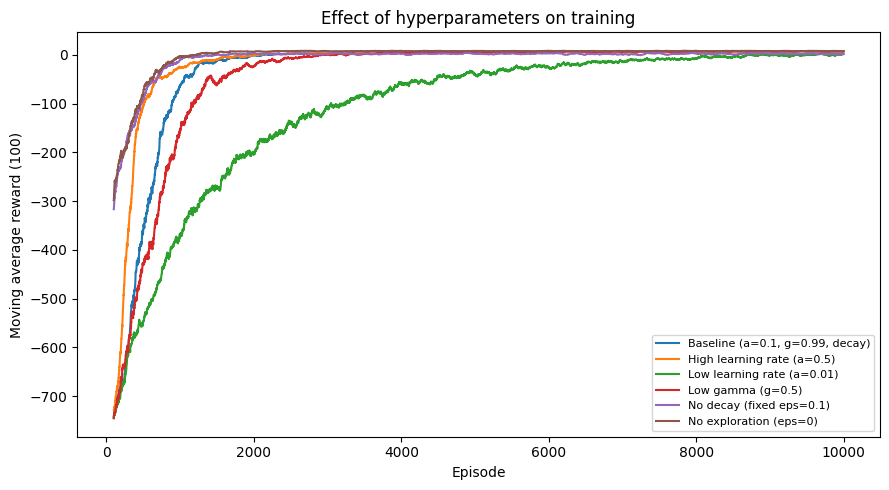

,Configuration,Test avg reward,Test avg steps,Test success %
0,"Baseline (a=0.1, g=0.99, decay)",7.63,13.37,100
1,High learning rate (a=0.5),7.57,13.43,100
2,Low learning rate (a=0.01),-129.52,120.43,42
3,Low gamma (g=0.5),-23.14,40.99,85
4,No decay (fixed eps=0.1),7.63,13.37,100
5,No exploration (eps=0),7.63,13.37,100


In [ ]:
import pandas as pd

configs = {
    "Baseline (a=0.1, g=0.99, decay)": dict(alpha=0.1, gamma=0.99, eps_decay=0.999),
    "High learning rate (a=0.5)":      dict(alpha=0.5, gamma=0.99, eps_decay=0.999),
    "Low learning rate (a=0.01)":      dict(alpha=0.01, gamma=0.99, eps_decay=0.999),
    "Low gamma (g=0.5)":               dict(alpha=0.1, gamma=0.5, eps_decay=0.999),
    "No decay (fixed eps=0.1)":        dict(alpha=0.1, gamma=0.99, eps_start=0.1, eps_min=0.1, eps_decay=1.0),
    "No exploration (eps=0)":          dict(alpha=0.1, gamma=0.99, eps_start=0.0, eps_min=0.0, eps_decay=1.0),
}

rows = []
plt.figure(figsize=(9, 5))

for name, params in configs.items():
    Q_i, r_i, s_i = train(episodes=10000, seed=0, **params)
    res = evaluate(Q_i, episodes=100)
    rows.append({
        "Configuration": name,
        "Test avg reward": round(res["avg_reward"], 2),
        "Test avg steps": round(res["avg_steps"], 2),
        "Test success %": round(res["success_rate"]),
    })
    plt.plot(range(99, len(r_i)), moving_average(r_i, 100), label=name)

plt.xlabel("Episode")
plt.ylabel("Moving average reward (100)")
plt.title("Effect of hyperparameters on training")
plt.legend(fontsize=8)
plt.tight_layout()
plt.savefig("hyperparameter_comparison.png", dpi=150)
plt.show()

df = pd.DataFrame(rows)
display(df)